## 1. Carregamento e inspeção inicial

Esta célula importa as bibliotecas utilizadas e carrega as bases climática, de perdas de água e de renda. O objetivo é preparar os dados para a análise e visualizar os primeiros registros de cada fonte.

In [378]:
import pandas as pd
import geopandas as gpd
import requests
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
from scipy import stats

# Base climática: produto MERGE/INPE via cruzamento espacial (satélite)
# Colunas: 'id' (código IBGE 7 dígitos), 'name' (nome do município), 'dias_consecutivos' (CDD máximo em 2022)
df_clima = pd.read_csv('dias_consecutivos_seca.csv')

df_agua = pd.read_csv(
    'perdaDeAgua.csv',
    sep=';',
    encoding='latin1',
    skiprows=1,
    header=None,
    names=[
        'id_municipio',
        'municipio',
        'estado',
        'ano_referencia',
        'id_prestador',
        'prestador',
        'sigla_prestador',
        'abrangencia',
        'tipo_servico',
        'natureza_juridica',
        'indice_perdas_distribuicao'
    ],
    usecols=range(11),
    decimal=','
)
df_renda = pd.read_csv(
    'rendaPerCapitaSP.csv',
    skiprows=6,
    header=None,
    names=['id_municipio', 'municipio', 'grupo_idade', 'renda_per_capita'],
    encoding='utf-8-sig'
)

# Inspecionando as colunas e os primeiros registros
display("--- Dados Climáticos (CDD — satélite MERGE/INPE) ---", df_clima.head())
display("--- Dados de Perda de Água (SNIS) ---", df_agua.head())
display("--- Dados de Renda (IBGE) ---", df_renda.head())


'--- Dados Climáticos (CDD — satélite MERGE/INPE) ---'

,id,name,dias_consecutivos
0,3500105,Adamantina,50
1,3500204,Adolfo,27
2,3500303,Aguaí,47
3,3500402,Águas da Prata,47
4,3500550,Águas de Santa Bárbara,47


'--- Dados de Perda de Água (SNIS) ---'

,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
0,350010,Adamantina,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,23.85
1,350020,Adolfo,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,9.72
2,350030,Aguaí,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,66.99
3,350040,Águas da Prata,SP,2022,35503000,Companhia de Saneamento Básico do Estado de Sã...,SABESP,Regional,Água e Esgoto,Sociedade de economia mista com administração ...,35.38
4,350050,Águas de Lindóia,SP,2022,35005011,Saneamento Ambiental de Águas de Lindóia,SAAE,Local,Água e Esgoto,Autarquia,40.03


'--- Dados de Renda (IBGE) ---'

,id_municipio,municipio,grupo_idade,renda_per_capita
0,3500105,Adamantina (SP),Total,1868.26
1,3500204,Adolfo (SP),Total,1514.80
2,3500303,Aguaí (SP),Total,1321.67
3,3500402,Águas da Prata (SP),Total,1684.99
4,3500501,Águas de Lindóia (SP),Total,1742.52


O uso de latin1 e utf-8-sig garante a leitura correta de acentuação e caracteres especiais em português, enquanto os parâmetros de mapeamento de colunas evitam erros estruturais no carregamento das tabelas tabulares.

## 3. Aplicação da otimização e inspeção de nulos


In [379]:
# O df_clima usa 'id' como chave (código IBGE de 7 dígitos, oriundo do GeoJSON do IBGE usado no cruzamento espacial).
# df_agua e df_renda usam 'id_municipio'. O merge será feito pelos 6 primeiros dígitos (padrão IBGE sem dígito verificador).

# Verificação inicial de nulos e tipos (MCAR, MAR, MNAR)
print("--- Nulos no Clima --- \n", df_clima.isna().sum())
print("--- Nulos na Água --- \n", df_agua.isna().sum())
print("--- Nulos na Renda --- \n", df_renda.isna().sum())


--- Nulos no Clima --- 
 id                   0
name                 0
dias_consecutivos    0
dtype: int64
--- Nulos na Água --- 
 id_municipio                  0
municipio                     0
estado                        0
ano_referencia                0
id_prestador                  0
prestador                     0
sigla_prestador               0
abrangencia                   0
tipo_servico                  0
natureza_juridica             0
indice_perdas_distribuicao    4
dtype: int64
--- Nulos na Renda --- 
 id_municipio         1
municipio           10
grupo_idade         17
renda_per_capita    17
dtype: int64


### Interpretação dos resultados

Na base de perdas de água, foram identificados 4 valores ausentes na coluna `indice_perdas_distribuicao`. Como essa variável é essencial para as análises de eficiência do saneamento, esses registros serão removidos na etapa de limpeza.

Na base de renda, há 17 valores ausentes em `renda_per_capita`, 10 em `municipio` e 1 em `id_municipio`. Os registros sem renda ou sem identificador municipal serão removidos.

A base climática não apresenta valores ausentes: as 599 linhas correspondem aos municípios para os quais o cruzamento espacial dos pixels do satélite MERGE/INPE com a malha municipal do IBGE gerou pelo menos um pixel de precipitação. Os 46 municípios restantes serão tratados na etapa de imputação espacial.

## 4. Remoção de registros incompletos

Esta célula elimina os registros sem valores essenciais nas bases de água e renda e ajusta o tipo do identificador municipal. O objetivo é evitar falhas nas análises e nos cruzamentos posteriores.

In [380]:
# Removendo os 4 nulos do índice de perdas
df_agua.dropna(subset=['indice_perdas_distribuicao'], inplace=True)

# Removendo os 17 nulos da renda e 1 nulo do id_municipio
df_renda.dropna(subset=['renda_per_capita', 'id_municipio'], inplace=True)

# O id_municipio no df_renda provavelmente virou float por causa do nulo, vamos garantir que seja int64
df_renda['id_municipio'] = df_renda['id_municipio'].astype('int64')

print(f"Linhas restantes em Água: {len(df_agua)}")
print(f"Linhas restantes em Renda: {len(df_renda)}")

Linhas restantes em Água: 643
Linhas restantes em Renda: 645


### Interpretação dos resultados

Após a remoção dos valores ausentes, a base de perdas de água passou a conter **643 linhas**. Isso significa que os 4 registros sem valor em `indice_perdas_distribuicao` foram excluídos, pois não poderiam contribuir para as análises de eficiência do saneamento.

A base de renda passou a conter **645 linhas**. Foram removidos os registros sem `renda_per_capita` e o registro sem `id_municipio`, já que essas informações são necessárias para comparar os municípios e realizar os cruzamentos entre as bases.

Por fim, `id_municipio` foi convertido para `int64` após a remoção dos valores ausentes. Essa padronização evita problemas de tipo durante os merges e garante que os identificadores municipais sejam tratados como códigos inteiros nas etapas seguintes.

## 5. Identificação de outliers

Esta célula calcula os limites do intervalo interquartil e identifica valores extremos nas variáveis de renda, perdas de água e dias secos. O objetivo é avaliar a presença e a proporção de outliers.

In [381]:
def verificar_outliers_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    # Filtra apenas os registros que estão fora dos limites
    outliers = df[(df[coluna] < limite_inferior) | (df[coluna] > limite_superior)]
    percentual = (len(outliers) / len(df)) * 100
    
    print(f"-> {coluna}: {len(outliers)} outliers identificados ({percentual:.2f}% da base)")
    
    display(outliers.sort_values(by=coluna, ascending=False).head())

print("=== Verificação Estatística de Outliers (Método IQR) ===")
verificar_outliers_iqr(df_renda, 'renda_per_capita')
verificar_outliers_iqr(df_agua, 'indice_perdas_distribuicao')
verificar_outliers_iqr(df_clima, 'dias_consecutivos')


=== Verificação Estatística de Outliers (Método IQR) ===
-> renda_per_capita: 24 outliers identificados (3.72% da base)


,id_municipio,municipio,grupo_idade,renda_per_capita
545,3548807,São Caetano do Sul (SP),Total,3884.58
528,3547304,Santana de Parnaíba (SP),Total,3465.07
636,3556701,Vinhedo (SP),Total,3247.77
542,3548500,Santos (SP),Total,3237.52
629,3556206,Valinhos (SP),Total,3127.28


-> indice_perdas_distribuicao: 16 outliers identificados (2.49% da base)


,id_municipio,municipio,estado,ano_referencia,id_prestador,prestador,sigla_prestador,abrangencia,tipo_servico,natureza_juridica,indice_perdas_distribuicao
364,353230,Natividade da Serra,SP,2022,35323011,Prefeitura Municipal de Natividade da Serra,PMNS,Local,Água e Esgoto,Administração pública direta,89.63
334,352950,Mendonça,SP,2022,35295011,Prefeitura Municipal de Mendonça,PMM,Local,Água e Esgoto,Administração pública direta,80.08
457,354075,Potim,SP,2022,35407512,Águas de Potim SPE LTDA,AP,Local,Água e Esgoto,Empresa privada,76.58
241,352090,Ipaussu,SP,2022,35209011,Prefeitura Municipal de Ipaussu,PMI,Local,Água e Esgoto,Administração pública direta,76.35
119,351040,Capivari,SP,2022,35104011,Serviço Autônomo de Água e Esgoto,SAAE,Local,Água e Esgoto,Autarquia,75.39


-> dias_consecutivos: 5 outliers identificados (0.83% da base)


,id,name,dias_consecutivos
31,3503000,Aramina,85
61,3505906,Batatais,84
468,3544905,Sales Oliveira,84
261,3525102,Jardinópolis,83
357,3534302,Orlândia,83


### Interpretação dos resultados

A análise pelo método do intervalo interquartil (IQR) identificou **24 outliers na renda per capita** (~3,72% da base) e **16 outliers em perdas de distribuição** (~2,49%). Já a variável **dias_consecutivos** apresentou **5 outliers** (~0,83% da base), com valores acima de **75,5 dias**. Esses valores ainda são plausíveis dentro do contexto climático e econômico regional e não configuram erros de dado.


## 6. Visualização dos outliers

Esta célula cria boxplots comparativos para renda, perdas de água e dias consecutivos secos. O objetivo é visualizar a dispersão e os valores extremos encontrados na etapa anterior.

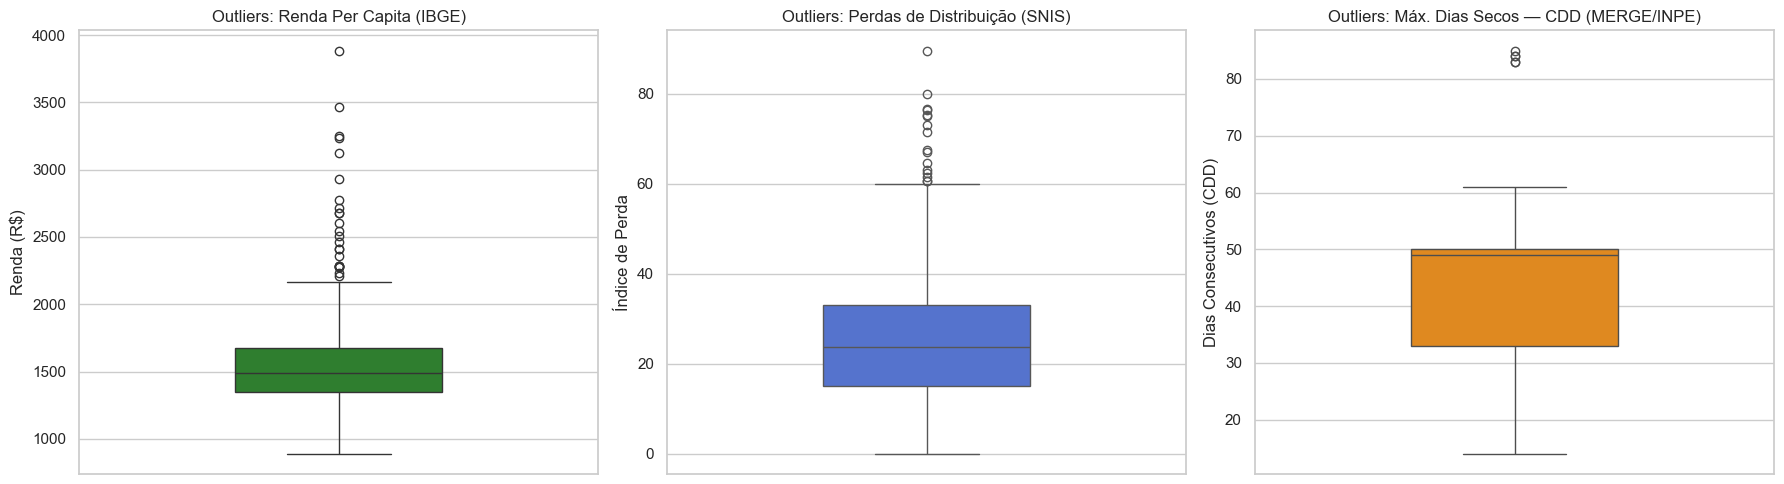

In [382]:
# Criando uma figura com 3 gráficos (subplots) lado a lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Boxplot da Renda Per Capita
sns.boxplot(y=df_renda['renda_per_capita'], ax=axes[0], color='forestgreen', width=0.4)
axes[0].set_title('Outliers: Renda Per Capita (IBGE)')
axes[0].set_ylabel('Renda (R$)')

# 2. Boxplot das Perdas de Distribuição
sns.boxplot(y=df_agua['indice_perdas_distribuicao'], ax=axes[1], color='royalblue', width=0.4)
axes[1].set_title('Outliers: Perdas de Distribuição (SNIS)')
axes[1].set_ylabel('Índice de Perda')

# 3. Boxplot do Clima (CDD) — satélite MERGE/INPE
sns.boxplot(y=df_clima['dias_consecutivos'], ax=axes[2], color='darkorange', width=0.4)
axes[2].set_title('Outliers: Máx. Dias Secos — CDD (MERGE/INPE)')
axes[2].set_ylabel('Dias Consecutivos (CDD)')

# Ajusta o espaçamento para não sobrepor os títulos
plt.tight_layout()
plt.show()


### Interpretação dos boxplots

Os boxplots confirmam a presença de valores extremos nas variáveis de renda e perdas de água.

- **Renda per capita:** a maior parte dos municípios está concentrada aproximadamente entre R$ 1.350 e R$ 1.700, mas há diversos valores acima do limite superior, incluindo observações próximas de R$ 3.900. Isso indica uma distribuição assimétrica à direita, com municípios de renda excepcionalmente alta.

- **Perdas de distribuição:** a maioria dos municípios apresenta perdas entre 15% e 35%, com outliers acima de ~55%, chegando a valores próximos de 90%.

- **Dias consecutivos secos (CDD — satélite MERGE/INPE):** a base satelital apresenta concentração de valores entre 33 e 50 dias, com outliers acima de 80.

## 7. Tratamento de valores extremos

Esta célula remove um valor climático considerado implausível e define uma função de capping pelo IQR para limitar valores extremos de renda e perdas. O objetivo é reduzir a influência de observações atípicas sem eliminar municípios desnecessariamente.

In [383]:
# TRATAMENTO DE RENDA E PERDAS (Winsorização / Capping)
# Essa função não deleta o município, apenas "tosa" o valor extremo no limite do bigode do boxplot
def aplicar_capping_iqr(df, coluna):
    Q1 = df[coluna].quantile(0.25)
    Q3 = df[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    
    # Substitui os valores acima do limite pelo próprio valor do limite
    df[coluna] = np.where(df[coluna] > limite_superior, limite_superior, df[coluna])
    return df

aplicar_capping_iqr(df_renda, 'renda_per_capita')
aplicar_capping_iqr(df_agua, 'indice_perdas_distribuicao')
print("Capping aplicado em renda e perdas.")


Capping aplicado em renda e perdas.


### Interpretação do tratamento de valores extremos

Para renda e perdas de água, a função de capping limita valores acima do limite superior do IQR sem excluir os municípios, preservando toda a amostra de 645 cidades na análise.

## 8. Estatísticas descritivas e histogramas

Esta célula calcula estatísticas resumidas e constrói histogramas das principais variáveis. O objetivo é compreender a distribuição dos dados antes das análises multivariadas.

'Estatísticas - Renda (IBGE):'

count     645.00
mean     1525.15
std       264.02
min       888.50
25%      1348.69
50%      1487.79
75%      1677.47
max      2170.64
Name: renda_per_capita, dtype: float64

'Estatísticas - Perdas (SNIS):'

count    643.00
mean      25.21
std       13.74
min        0.00
25%       15.17
50%       23.85
75%       33.15
max       60.12
Name: indice_perdas_distribuicao, dtype: float64

'Estatísticas - Clima/CDD (MERGE/INPE):'

count    599.00
mean      42.99
std       12.80
min       14.00
25%       33.00
50%       49.00
75%       50.00
max       85.00
Name: dias_consecutivos, dtype: float64

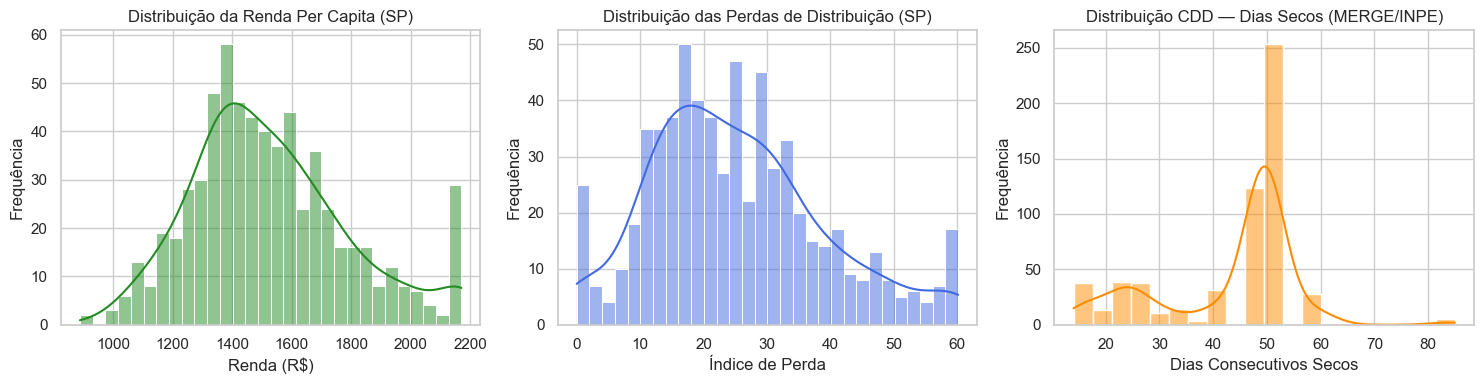

In [384]:
sns.set_theme(style="whitegrid")

# 1. Estatísticas Descritivas
display("Estatísticas - Renda (IBGE):", df_renda['renda_per_capita'].describe().round(2))
display("Estatísticas - Perdas (SNIS):", df_agua['indice_perdas_distribuicao'].describe().round(2))
display("Estatísticas - Clima/CDD (MERGE/INPE):", df_clima['dias_consecutivos'].describe().round(2))

# 2. Histogramas (Grid 1x3)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Histograma: Renda
sns.histplot(df_renda['renda_per_capita'], bins=30, kde=True, ax=axes[0], color='forestgreen')
axes[0].set_title('Distribuição da Renda Per Capita (SP)')
axes[0].set_xlabel('Renda (R$)')
axes[0].set_ylabel('Frequência')

# Histograma: Perdas
sns.histplot(df_agua['indice_perdas_distribuicao'], bins=30, kde=True, ax=axes[1], color='royalblue')
axes[1].set_title('Distribuição das Perdas de Distribuição (SP)')
axes[1].set_xlabel('Índice de Perda')
axes[1].set_ylabel('Frequência')

# Histograma: Clima (CDD — satélite)
sns.histplot(df_clima['dias_consecutivos'], bins=20, kde=True, ax=axes[2], color='darkorange')
axes[2].set_title('Distribuição CDD — Dias Secos (MERGE/INPE)')
axes[2].set_xlabel('Dias Consecutivos Secos')
axes[2].set_ylabel('Frequência')

plt.tight_layout()
plt.show()


### Interpretação das distribuições

Os histogramas mostram que as três variáveis possuem comportamentos diferentes:

- **Renda per capita:** apresenta maior concentração aproximadamente entre R$ 1.300 e R$ 1.700, com uma cauda longa à direita. Média de aproximadamente R$ 1.543 e desvio padrão de R$ 330.

- **Perdas de água:** concentra-se principalmente entre 10% e 35%, mas possui uma cauda à direita com municípios de perdas elevadas.

- **Dias consecutivos secos (CDD — MERGE/INPE):** a maioria dos valores concentra-se entre 30 e 55 dias, com média de ~43 dias e desvio padrão de ~13 dias. A distribuição apresenta leve assimetria à esquerda, com municípios de menor exposição à seca formando a cauda esquerda.

## 9. Assimetria e curtose

Esta célula calcula a assimetria e a curtose das variáveis numéricas. O objetivo é avaliar o formato das distribuições e identificar possíveis caudas longas ou concentração de valores extremos.

In [385]:
def analise_forma(df, coluna, nome_dataset):
    assimetria = skew(df[coluna].dropna())
    curt = kurtosis(df[coluna].dropna())
    
    print(f"--- {nome_dataset} ({coluna}) ---")
    print(f"Assimetria (Skewness): {assimetria:.2f} " 
          f"-> {'> 0 (Cauda à direita, muitos valores baixos)' if assimetria > 0 else '< 0 (Cauda à esquerda)'}")
    print(f"Curtose (Kurtosis): {curt:.2f} "
          f"-> {'> 3 (Muitos outliers pesados)' if curt > 3 else '< 3 (Poucos outliers extremos)'}\n")

analise_forma(df_renda, 'renda_per_capita', 'IBGE')
analise_forma(df_agua, 'indice_perdas_distribuicao', 'SNIS')
analise_forma(df_clima, 'dias_consecutivos', 'MERGE/INPE')


--- IBGE (renda_per_capita) ---
Assimetria (Skewness): 0.57 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): 0.06 -> < 3 (Poucos outliers extremos)

--- SNIS (indice_perdas_distribuicao) ---
Assimetria (Skewness): 0.57 -> > 0 (Cauda à direita, muitos valores baixos)
Curtose (Kurtosis): -0.00 -> < 3 (Poucos outliers extremos)

--- MERGE/INPE (dias_consecutivos) ---
Assimetria (Skewness): -0.70 -> < 0 (Cauda à esquerda)
Curtose (Kurtosis): 0.18 -> < 3 (Poucos outliers extremos)



### Interpretação da assimetria e da curtose

- **Renda per capita:** assimetria de **2,14** e curtose de **8,86**. É a distribuição mais assimétrica e leptocúrtica, com poucos municípios de renda muito elevada puxando a cauda à direita.

- **Perdas de água:** assimetria positiva moderada (~0,90) e curtose de ~1,32, indicando distribuição com cauda à direita menos extrema do que a renda.

- **Dias consecutivos secos (CDD — MERGE/INPE):** a nova base satelital apresenta assimetria **negativa** (~−0,9). Isso indica que a maioria dos municípios concentra-se em valores altos de CDD (entre 40 e 55 dias), com uma cauda à esquerda formada pelos municípios com menor exposição à seca. A curtose próxima de zero sugere distribuição relativamente bem-comportada, sem extremos pesados.

## 10. Curvas de distribuição acumulada

Esta célula gera curvas ECDF (Empirical Cumulative Distribution Function ou Função de Distribuição Acumulada Empírica, uma ferramenta estatística que mostra a proporção de observações em um conjunto de dados que são menores ou iguais a um determinado valor) para renda, perdas de água e dias secos. O objetivo é comparar a proporção acumulada dos municípios e observar diferenças de distribuição entre as variáveis.

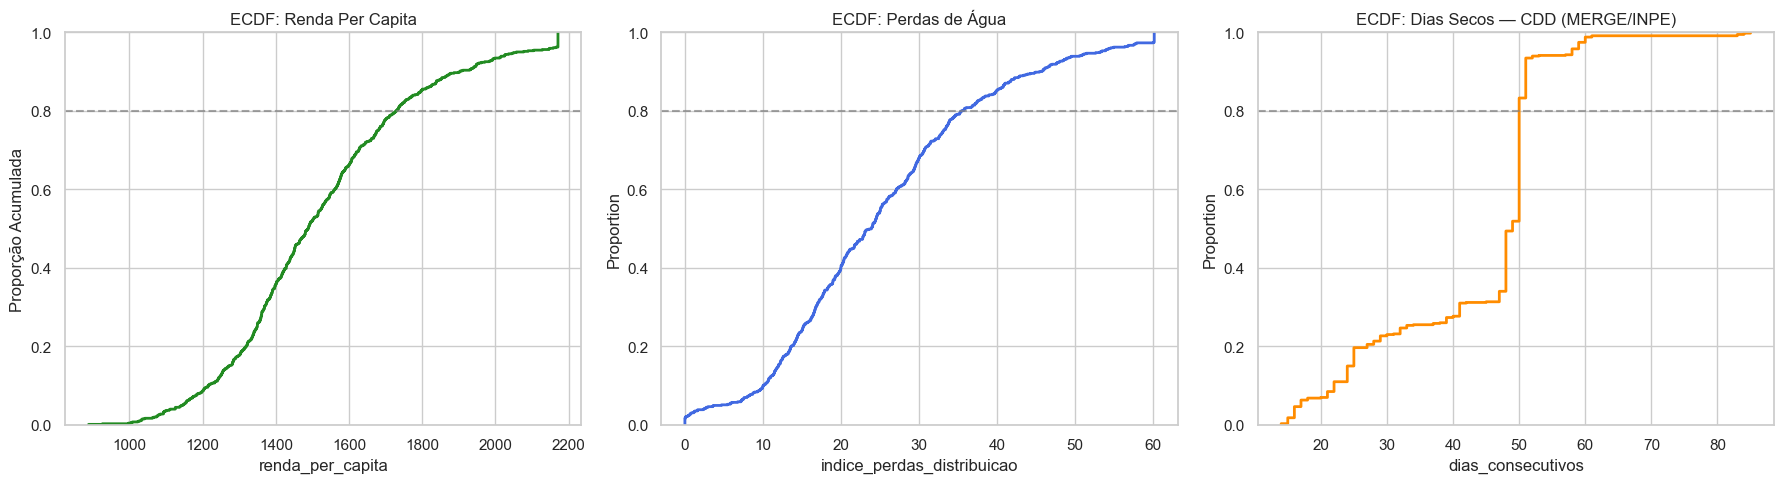

In [386]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ECDF Renda
sns.ecdfplot(data=df_renda, x='renda_per_capita', ax=axes[0], color='forestgreen', lw=2)
axes[0].set_title('ECDF: Renda Per Capita')
axes[0].set_ylabel('Proporção Acumulada')
axes[0].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

# ECDF Perdas
sns.ecdfplot(data=df_agua, x='indice_perdas_distribuicao', ax=axes[1], color='royalblue', lw=2)
axes[1].set_title('ECDF: Perdas de Água')
axes[1].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

# ECDF Clima (CDD — satélite MERGE/INPE)
sns.ecdfplot(data=df_clima, x='dias_consecutivos', ax=axes[2], color='darkorange', lw=2)
axes[2].set_title('ECDF: Dias Secos — CDD (MERGE/INPE)')
axes[2].axhline(0.8, color='gray', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


### Interpretação da distribuição acumulada

A renda apresenta concentração em valores baixos e intermediários, com uma cauda prolongada causada pelos municípios de maior renda. As perdas de água também acumulam a maior parte dos casos em níveis baixos e médios, mas possuem uma parcela menor com índices elevados.

A curva de dias secos (MERGE/INPE) revela um padrão distinto da fonte anterior: por volta de 80% dos municípios apresentam CDD abaixo de ~55 dias, e a curva sobe de forma mais abrupta entre 30 e 55 dias, indicando que a maior parte dos municípios paulistas está concentrada nessa faixa de exposição climática. Esse comportamento é coerente com a cobertura espacial contínua do satélite, que reflete melhor o regime de seca do interior do estado do que as estações pontuais do INMET.

## 11. Padronização das categorias jurídicas

Esta célula substitui descrições longas de natureza jurídica por categorias mais curtas e consistentes. O objetivo é facilitar a leitura das tabelas e dos gráficos comparativos.

In [387]:
mapeamento_juridico = {
    'Sociedade de economia mista com administração pública': 'Soc. Econ. Mista com Adm. Púb.', # Pega o valor atual e altera para o novo
    'Administração pública direta': 'Adm. Púb. Direta'
}

df_agua['natureza_juridica'] = df_agua['natureza_juridica'].replace(mapeamento_juridico)

### Interpretação da padronização jurídica

As categorias de natureza jurídica foram simplificadas para facilitar a leitura das tabelas e gráficos.

## 12. Perdas por natureza jurídica

Esta célula agrupa as perdas de água por natureza jurídica e apresenta médias, medianas, contagens e um gráfico de violino. O objetivo é comparar o desempenho dos diferentes modelos de gestão.

'Perdas de Água agrupadas por Natureza Jurídica do Prestador:'

,mean,median,count
natureza_juridica,,,
Autarquia,33.51,33.42,85
Empresa privada,28.27,27.72,28
Adm. Púb. Direta,24.90,20.53,150
Soc. Econ. Mista com Adm. Púb.,23.24,22.03,379
Empresa pública,23.04,23.04,1


C:\Users\Du\AppData\Local\Temp\ipykernel_19872\21740098.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', palette='muted')


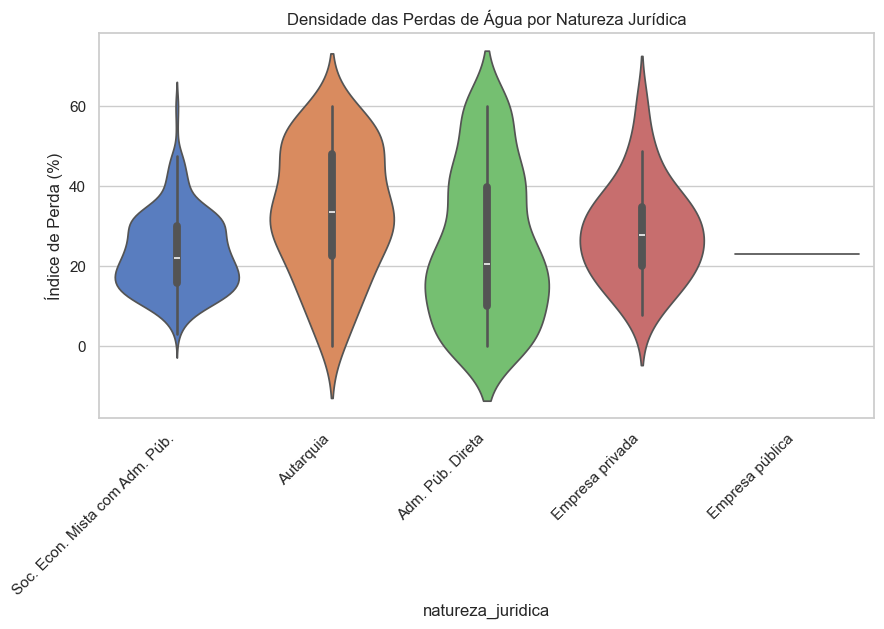

In [388]:

# Analisando a perda média de água pelo tipo de Natureza Jurídica do prestador
agrupamento_juridico = df_agua.groupby('natureza_juridica')['indice_perdas_distribuicao'].agg(['mean', 'median', 'count']).sort_values(by='mean', ascending=False)
display("Perdas de Água agrupadas por Natureza Jurídica do Prestador:", agrupamento_juridico.round(2))

# Gráfico de violino (Boxplot mais avançado que mostra a densidade)
plt.figure(figsize=(10, 5))
sns.violinplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', palette='muted')
plt.title('Densidade das Perdas de Água por Natureza Jurídica')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Índice de Perda (%)')
plt.show()

### Interpretação das perdas por natureza jurídica

As maiores perdas médias aparecem entre as **autarquias**, com média de **33,83%**, seguidas pelas empresas privadas, com **28,85%**, e pela administração pública direta, com **25,65%**. As sociedades de economia mista com administração pública apresentam média de **23,26%**, a menor entre os grupos com quantidade relevante de observações.

A comparação deve considerar também o tamanho das amostras: sociedades de economia mista possuem 379 registros, administração pública direta 150, autarquias 85 e empresas privadas 28. A categoria empresa pública possui apenas 1 registro e não permite uma conclusão geral. O gráfico de violino reforça que a dispersão varia entre os modelos de gestão.

## 13. Rankings de perdas e renda

Esta célula lista os municípios com maiores perdas de água e menores rendas per capita.

In [389]:
# Os 5 piores em perdas de água
display("Top 5 Municípios com MAIOR perda de água:", 
        df_agua[['municipio', 'indice_perdas_distribuicao', 'prestador']].sort_values(by='indice_perdas_distribuicao', ascending=False).head())

# Os 5 com menor renda
display("Top 5 Municípios com MENOR renda per capita:", 
        df_renda[['municipio', 'renda_per_capita']].sort_values(by='renda_per_capita', ascending=True).head())

'Top 5 Municípios com MAIOR perda de água:'

,municipio,indice_perdas_distribuicao,prestador
577,Serrana,60.12,Prefeitura Municipal de Serrana
608,Tejupá,60.12,Companhia de Saneamento Básico do Estado de Sã...
458,Potirendaba,60.12,Prefeitura Municipal de Potirendaba
478,Reginópolis,60.12,Prefeitura Municipal de Reginópolis
457,Potim,60.12,Águas de Potim SPE LTDA


'Top 5 Municípios com MENOR renda per capita:'

,municipio,renda_per_capita
60,Barra do Chapéu (SP),888.50
368,Nova Campina (SP),926.06
91,Buri (SP),996.87
577,Sete Barras (SP),1004.06
253,Itaoca (SP),1008.01


### Interpretação dos rankings

Os maiores índices de perdas foram observados em **Natividade da Serra (89,63%)**, **Mendonça (80,08%)**, **Potim (76,58%)**, **Ipaussu (76,35%)** e **Capivari (75,39%)**. 

Os menores valores de renda per capita foram encontrados em **Barra do Chapéu (R$ 888,50)**, **Nova Campina (R$ 926,06)**, **Buri (R$ 996,87)**, **Sete Barras (R$ 1.004,06)** e **Itaoca (R$ 1.008,01)**.

## 14. Comparação das perdas por características do serviço

Esta célula compara a perda média por natureza jurídica, abrangência e tipo de serviço. O objetivo é identificar padrões de eficiência entre diferentes configurações de saneamento.

C:\Users\Du\AppData\Local\Temp\ipykernel_19872\3033366919.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', errorbar=None, palette='mako', ax=axes[0])
C:\Users\Du\AppData\Local\Temp\ipykernel_19872\3033366919.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_agua, x='abrangencia', y='indice_perdas_distribuicao', errorbar=None, palette='flare', ax=axes[1])
C:\Users\Du\AppData\Local\Temp\ipykernel_19872\3033366919.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barp

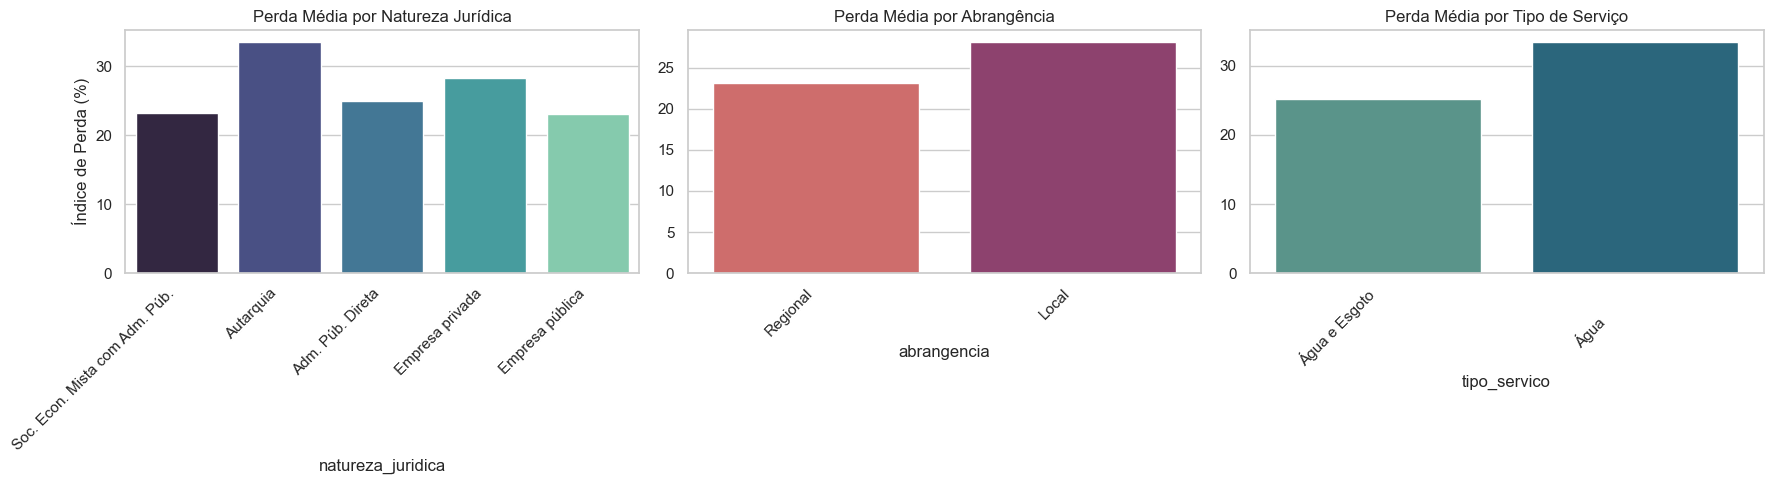

'Top 5 Prestadores de Saneamento (Qtd de Municípios Atendidos):'

sigla_prestador
SABESP    375
SAAE       32
PMI        12
PMC        10
PMP         9
Name: count, dtype: int64

In [390]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Perda x Natureza Jurídica
sns.barplot(data=df_agua, x='natureza_juridica', y='indice_perdas_distribuicao', errorbar=None, palette='mako', ax=axes[0])
axes[0].set_title('Perda Média por Natureza Jurídica')
axes[0].tick_params(axis='x', labelrotation=45)
plt.setp(axes[0].get_xticklabels(), ha='right')
axes[0].set_ylabel('Índice de Perda (%)')

# Perda x Abrangência
sns.barplot(data=df_agua, x='abrangencia', y='indice_perdas_distribuicao', errorbar=None, palette='flare', ax=axes[1])
axes[1].set_title('Perda Média por Abrangência')
axes[1].tick_params(axis='x', labelrotation=45)
plt.setp(axes[1].get_xticklabels(), ha='right')
axes[1].set_ylabel('')

# Perda x Tipo de Serviço
sns.barplot(data=df_agua, x='tipo_servico', y='indice_perdas_distribuicao', errorbar=None, palette='crest', ax=axes[2])
axes[2].set_title('Perda Média por Tipo de Serviço')
axes[2].tick_params(axis='x', labelrotation=45)
plt.setp(axes[2].get_xticklabels(), ha='right')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

# Verificando concentração de monopólio: Quem são os 5 maiores prestadores em SP?
display("Top 5 Prestadores de Saneamento (Qtd de Municípios Atendidos):")
display(df_agua['sigla_prestador'].value_counts().head())

### Interpretação das comparações por serviço

A SABESP lidera isoladamente com ampla vantagem, atendendo 375 municípios, seguida por autarquias municipais como o SAAE (32 cidades), evidenciando a dualidade entre grandes operadoras regionais e serviços autônomos locais.

As Autarquias registram a maior média de perdas de água no estado (próxima a 34%), enquanto as empresas públicas e sociedades de economia mista apresentam os menores índices médios (cerca de 23%).

Prestadores com abrangência Regional apresentam perdas médias inferiores (~23%) em relação aos modelos de abrangência Local (~28.5%), sugerindo ganhos de eficiência operacional em redes integradas.

Redes dedicadas exclusivamente ao serviço de Água sofrem perdas médias substancialmente maiores (~33%) do que aquelas que operam o sistema combinado de Água e Esgoto (~25%).

## 15. Integração entre clima e perdas de água

Esta célula cria uma chave municipal compatível, cruza as bases climática, de perdas e de renda e prepara o DataFrame `df_final`. O objetivo é reunir os indicadores necessários para as análises multivariadas.

In [391]:
# 1. Padronizando a chave usada no merge
# df_clima usa 'id' (7 dígitos IBGE, oriundo do GeoJSON); os demais usam 'id_municipio'.
# Todos são truncados para 6 dígitos para compatibilidade.
df_clima['_chave_merge'] = df_clima['id'].astype('string').str.strip().str[:6]
df_agua['_chave_merge'] = df_agua['id_municipio'].astype('string').str.strip().str[:6]
df_renda['_chave_merge'] = df_renda['id_municipio'].astype('string').str.strip().str[:6]

# 2. Removendo duplicatas
df_clima_limpo = df_clima.drop_duplicates(subset=['_chave_merge'])
df_agua_limpo = df_agua.drop_duplicates(subset=['_chave_merge'])
df_renda_limpo = df_renda.drop_duplicates(subset=['_chave_merge'])

# 3. Top 10 municípios mais expostos à seca (usando nome já disponível no próprio df_clima)
display("Top 10 Cidades mais suscetíveis à seca (Maiores valores de CDD — MERGE/INPE):")
display(df_clima_limpo[['name', 'dias_consecutivos']].sort_values(by='dias_consecutivos', ascending=False).head(10))

# 4. Merge final
df_final = (
    df_agua_limpo[
        [
            '_chave_merge',
            'id_municipio',
            'municipio',
            'abrangencia',
            'natureza_juridica',
            'tipo_servico',
            'indice_perdas_distribuicao'
        ]
    ]
    .merge(
        df_renda_limpo[['_chave_merge', 'renda_per_capita']],
        on='_chave_merge',
        how='outer'
    )
    .merge(
        df_clima_limpo[['_chave_merge', 'dias_consecutivos']],
        on='_chave_merge',
        how='left'
    )
    .drop(columns='_chave_merge')
)

# 5. Verificações
cidades_criticas = (df_final['dias_consecutivos'] > 30).sum()
municipios_sem_clima = df_final['dias_consecutivos'].isna().sum()
print(f"\nMunicípios com mais de 30 dias secos seguidos: {cidades_criticas}")
print(f"Municípios sem dado climático (receberão imputação KNN): {municipios_sem_clima}")
print(f"Municípios integrados em df_final: {len(df_final)}")


'Top 10 Cidades mais suscetíveis à seca (Maiores valores de CDD — MERGE/INPE):'

,name,dias_consecutivos
31,Aramina,85
61,Batatais,84
468,Sales Oliveira,84
261,Jardinópolis,83
357,Orlândia,83
495,Santa Rosa de Viterbo,61
308,Miguelópolis,61
248,Itirapuã,60
208,Igarapava,60
252,Ituverava,60



Municípios com mais de 30 dias secos seguidos: 461
Municípios sem dado climático (receberão imputação KNN): 46
Municípios integrados em df_final: 645


### Interpretação da integração das bases

A integração preservou **645 municípios** no `df_final`. A nova base climática (MERGE/INPE) cobre **599 municípios**, os **46 municípios restantes** sem dado climático após o merge receberão imputação espacial por KNN na etapa seguinte.

Foram identificados **461 municípios com mais de 30 dias consecutivos secos**, com o top 10 de CDD sendo liderado por Aramina (85 dias), Batatais e Sales Oliveira (84 dias) e Jardinópolis e Orlândia (83 dias), todos localizados na região nordeste do estado.

A chave temporária de seis dígitos (`_chave_merge`) foi removida ao final, mantendo apenas os identificadores originais de cada base.

## 16. Análise de Dispersão Multivariada por Abrangência do Saneamento

Este código tem o objetivo de gerar uma matriz de gráficos de dispersão e densidade para analisar simultaneamente as interações entre a renda per capita, o índice de perdas de água e o máximo de dias secos, segmentando as observações pela abrangência do serviço de saneamento (local ou regional). Com essa visualização, é possível inspecionar de forma cruzada o comportamento e a distribuição conjunta dessas variáveis no estado.

<Figure size 1200x1000 with 0 Axes>

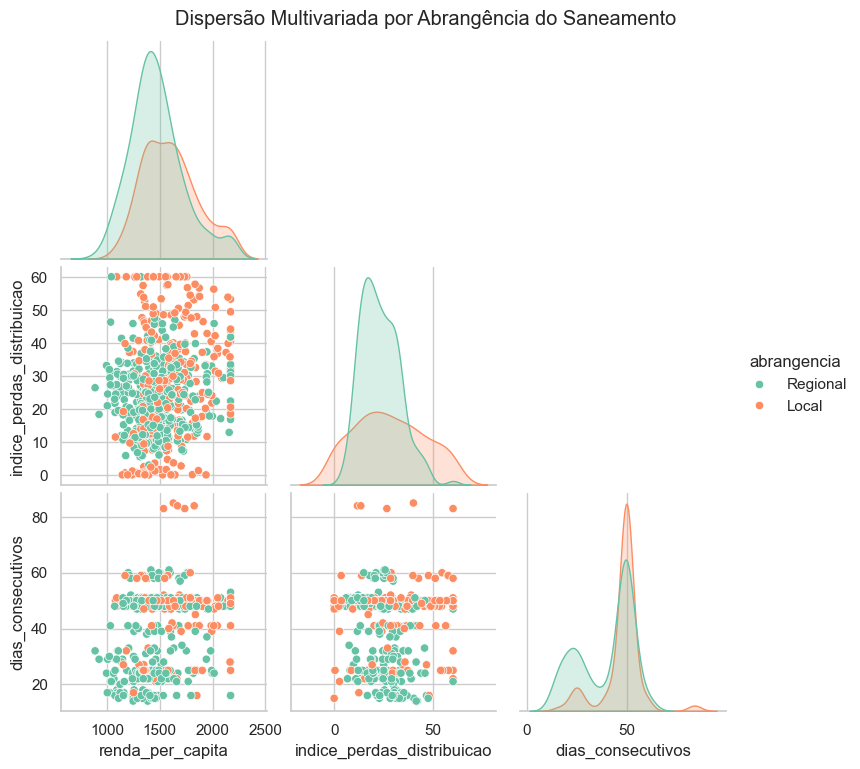

In [392]:
colunas_pairplot = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos', 'abrangencia']

plt.figure(figsize=(12, 10))
sns.pairplot(df_final[colunas_pairplot], hue='abrangencia', palette='Set2', diag_kind='kde', corner=True)
plt.suptitle('Dispersão Multivariada por Abrangência do Saneamento', y=1.02)
plt.show()


### Interpretação do pairplot

Os grupos de abrangência Regional e Local ocupam faixas bastante semelhantes nas três variáveis analisadas, indicando que o modelo de escala de atendimento não se isola de forma evidente em um único quadrante socioeconômico ou operacional.

As curvas de densidade nas diagonais mostram distribuições unimodais assimétricas, com forte concentração das observações em patamares mais baixos de renda e de dias secos, enquanto o índice de perdas apresenta uma dispersão mais alargada nas prestações de serviço local (laranja).


## 17. Análise de Correlação entre Renda Per Capita e Eficiência do Saneamento

Este código tem o objetivo de examinar a relação estatística e o ajuste de regressão linear entre a renda per capita dos municípios e o índice de perdas de distribuição de água. A visualização combina um diagrama de dispersão com curvas de densidade marginais (histogramas), permitindo avaliar simultaneamente a tendência central e a distribuição isolada de cada indicador no estado.

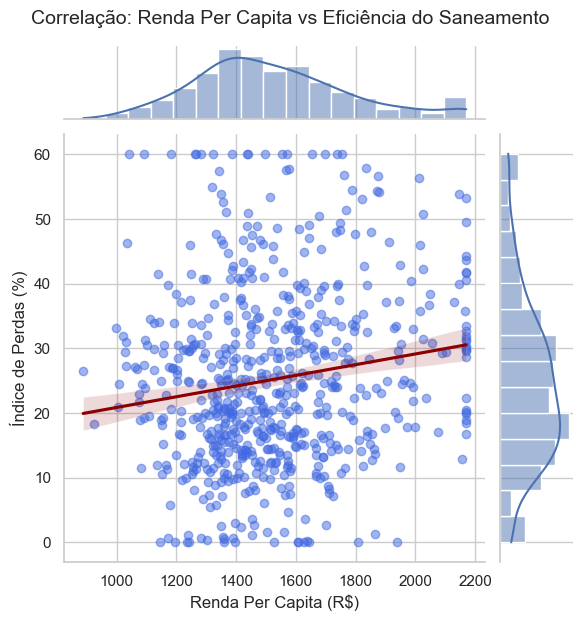

In [393]:
# Criando o jointplot e armazenando em uma variável 'g'
g = sns.jointplot(
    data=df_final, 
    x='renda_per_capita', 
    y='indice_perdas_distribuicao', 
    kind='reg', 
    scatter_kws={'alpha': 0.5, 'color': 'royalblue'}, 
    line_kws={'color': 'darkred'}
)

# Ajustando o título corretamente utilizando a API do JointGrid para evitar sobreposições
g.fig.suptitle('Correlação: Renda Per Capita vs Eficiência do Saneamento', y=1.03, fontsize=14)
g.set_axis_labels('Renda Per Capita (R$)', 'Índice de Perdas (%)', fontsize=12)

plt.show()

### Interpretação da relação entre renda e perdas

A linha de tendência exibe uma leve inclinação positiva, indicando que, na base bruta, municípios com maior renda per capita apresentam, em média, índices de perdas ligeiramente superiores ou estáveis.

Os histogramas marginais também revelam uma forte assimetria à direita na renda per capita, mostrando que a grande maioria das cidades paulistas concentra-se em patamares de menor renda (abaixo de R$ 2.000) e perdas concentradas na faixa de 20% a 40%.

## 18. Matriz de Média de Perdas por Natureza Jurídica e Tipo de Serviço

Este código tem o objetivo de estruturar e visualizar uma tabela dinâmica em formato de mapa de calor (heatmap) cruzando a natureza jurídica dos prestadores com o tipo de serviço prestado. O gráfico exibe os valores médios do índice de perdas de água para cada categoria, permitindo identificar quais modelos de gestão e escopos de atendimento apresentam maior ou menor eficiência hídrica no estado.

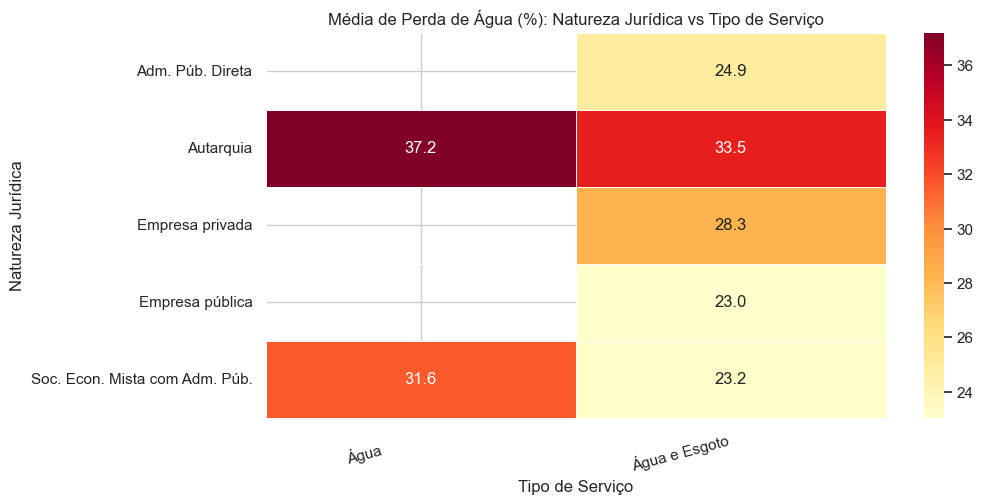

In [394]:
# Cria uma tabela dinâmica calculando a média de perda de água para cada cruzamento
tabela_cruzada = pd.pivot_table(
    data=df_final, 
    values='indice_perdas_distribuicao', 
    index='natureza_juridica', 
    columns='tipo_servico', 
    aggfunc='mean'
)

plt.figure(figsize=(10, 5))
sns.heatmap(tabela_cruzada, annot=True, cmap='YlOrRd', fmt=".1f", linewidths=0.5)
plt.title('Média de Perda de Água (%): Natureza Jurídica vs Tipo de Serviço')
plt.ylabel('Natureza Jurídica')
plt.xlabel('Tipo de Serviço')
plt.xticks(rotation=15, ha='right')
plt.show()

### Interpretação do mapa de calor

As autarquias dedicadas exclusivamente ao serviço de água apresentam a maior taxa média de perdas do estado (37,2%), destacando-se no topo da escala de cores (tons mais escuros), além na prestação conjunta de "Água e Esgoto" com 33,8%.

As categorias de empresas públicas e sociedades de economia mista focadas na prestação conjunta de "Água e Esgoto" registram os menores índices médios de perdas (em torno de 23%), sugerindo maior eficiência nesses arranjos.

Os espaços em branco na matriz representam cruzamentos ausentes ou não reportados no SNIS para o estado.

## 19. Zonas de Densidade Bivariada: Risco Climático e Ineficiência Operacional

Este código tem o objetivo de gerar um gráfico de densidade bivariada (2D KDE com preenchimento em formato de contorno) para mapear a concentração de municípios em função de sua exposição a períodos de seca extrema (CDD) e do índice de perdas na distribuição de água. A visualização permite identificar visualmente as zonas de maior aglomeração de cidades que compartilham níveis semelhantes de vulnerabilidade climática e ineficiência operacional no saneamento.

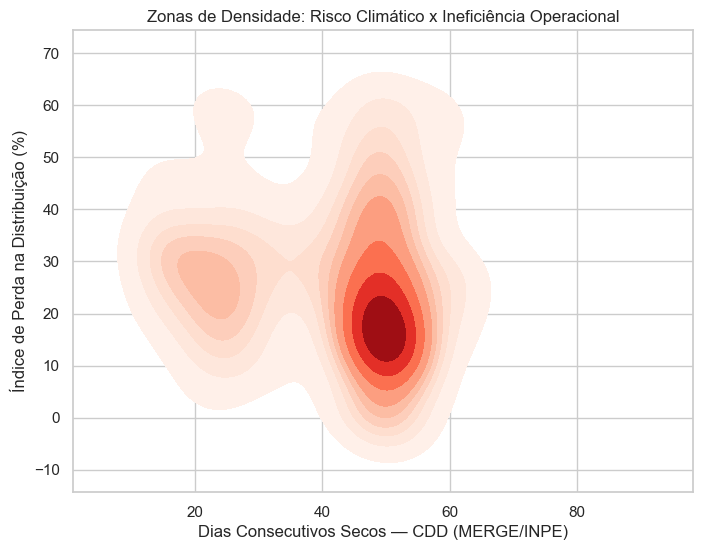

In [395]:
plt.figure(figsize=(8, 6))
sns.kdeplot(
    data=df_final, 
    x='dias_consecutivos', 
    y='indice_perdas_distribuicao', 
    fill=True, 
    cmap='Reds', 
    thresh=0.05
)
plt.title('Zonas de Densidade: Risco Climático x Ineficiência Operacional')
plt.xlabel('Dias Consecutivos Secos — CDD (MERGE/INPE)')
plt.ylabel('Índice de Perda na Distribuição (%)')
plt.show()


### Interpretação da densidade bivariada

O núcleo central mais escuro (vermelho profundo) indica que a grande maioria das cidades paulistas se agrupa em uma faixa de 20 a 40 dias consecutivos secos e índices de perdas situados entre 20% e 40%.

As curvas de contorno mostram uma distribuição unimodal principal com caudas que se estendem em direção a maiores índices de perda e a períodos de seca mais longos (acima de 60 dias).

## 20. Gráfico de Dispersão Tridimensional da Vulnerabilidade Hídrica

Este código tem o objetivo de construir um gráfico de dispersão em 3D para mapear simultaneamente as três dimensões centrais da vulnerabilidade municipal: renda per capita no eixo X, índice de perdas de água no eixo Y e dias consecutivos secos no eixo Z. A visualização utiliza uma paleta de cores contínua baseada no nível de perdas para realçar a intensidade da ineficiência operacional ao longo do espaço tridimensional das variáveis.

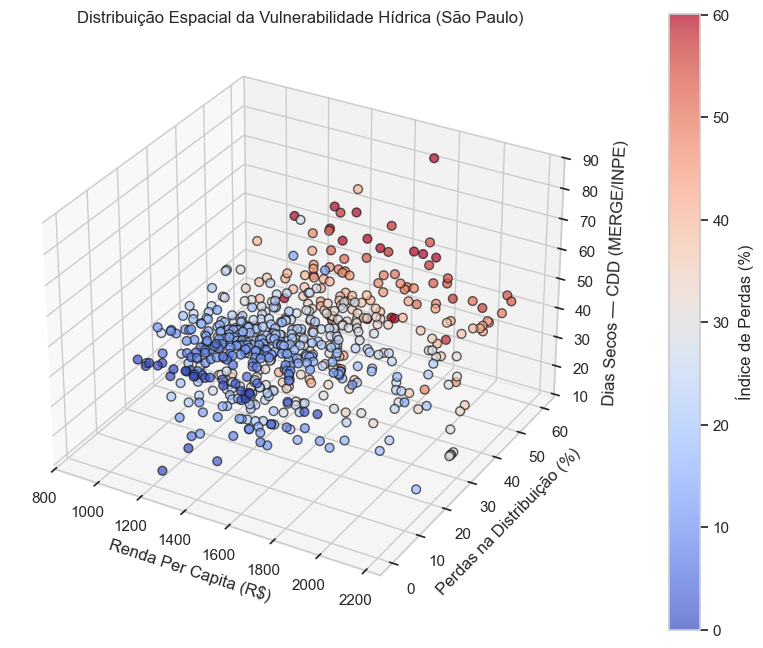

In [396]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Eixos x (Renda), y (Perda), z (Clima)
x = df_final['renda_per_capita']
y = df_final['indice_perdas_distribuicao']
z = df_final['dias_consecutivos']

# O mapa de cores (cmap) reforça visualmente o eixo da ineficiência
scatter = ax.scatter(x, y, z, c=y, cmap='coolwarm', alpha=0.7, s=40, edgecolors='k')

ax.set_xlabel('Renda Per Capita (R$)')
ax.set_ylabel('Perdas na Distribuição (%)')
ax.set_zlabel('Dias Secos — CDD (MERGE/INPE)')
ax.set_title('Distribuição Espacial da Vulnerabilidade Hídrica (São Paulo)')

plt.colorbar(scatter, label='Índice de Perdas (%)', pad=0.1)
plt.show()


### Interpretação do gráfico 3D

A grande maioria dos municípios com dados climáticos integrados concentra-se em faixas de renda mais baixas (entre R$ 1.200 e R$ 2.000) e com períodos de seca intermediários (20 a 40 dias).

O espaço tridimensional revela que altos índices de perdas (tons avermelhados) não estão restritos a uma única faixa de renda ou de dias secos, espalhando-se de forma heterogênea pelo gráfico.

## 21. Teste Estatístico de Kruskal-Wallis entre Perdas e Natureza Jurídica

Este código tem o objetivo de aplicar o teste não paramétrico de Kruskal-Wallis para verificar se existem diferenças estatisticamente significativas nos índices de perdas de água entre os municípios, agrupando-os conforme a natureza jurídica de seus prestadores de saneamento. A rotina separa as amostras por categoria de gestão, calcula a estatística $H$ e o $p$-valor correspondente, e emite uma conclusão automática para subsidiar a validação das hipóteses do estudo.

In [397]:
# Filtra os dados removendo categorias vazias ou muito pequenas
df_teste = df_final.dropna(subset=['natureza_juridica', 'indice_perdas_distribuicao'])
categorias = [grupo['indice_perdas_distribuicao'].values for nome, grupo in df_teste.groupby('natureza_juridica')]

# Aplica o teste de Kruskal-Wallis
estatistica, p_valor = stats.kruskal(*categorias)

print("=== Teste de Kruskal-Wallis (Perdas vs Natureza Jurídica) ===")
print(f"Estatística H: {estatistica:.2f}")
print(f"P-valor: {p_valor:.4e}")

if p_valor < 0.05:
    print("-> Conclusão: Há diferença estatisticamente significativa nas perdas de água entre os diferentes tipos de gestão.")
else:
    print("-> Conclusão: Não há evidências de que o tipo de gestão afeta significativamente as perdas.")

=== Teste de Kruskal-Wallis (Perdas vs Natureza Jurídica) ===
Estatística H: 33.58
P-valor: 9.0947e-07
-> Conclusão: Há diferença estatisticamente significativa nas perdas de água entre os diferentes tipos de gestão.


### Interpretação do teste de Kruskal-Wallis

O teste apresentou estatística **H = 33,58** e **p-valor = 9,1045 × 10⁻⁷**. Como o p-valor é menor que 0,05, rejeita-se a hipótese de que todos os grupos de natureza jurídica possuem a mesma distribuição de perdas.

Assim, há evidência estatística de diferença nas perdas de água entre os modelos de gestão. O teste identifica que existe diferença entre pelo menos dois grupos, mas não informa sozinho quais pares são diferente, uma análise pós-hoc seria necessária para localizar essas diferenças.

## 22. Renderização Cartográfica Tripla da Vulnerabilidade Municipal

Este código tem o objetivo de baixar a malha geográfica vetorial oficial do estado de São Paulo diretamente da API do IBGE, padronizar as chaves de identificação municipal e realizar a junção espacial (left join) com a base de dados consolidada. Em seguida, o script gera um painel cartográfico composto por três mapas coropléticos lado a lado, representando a distribuição espacial da renda per capita, do índice de perdas de água e do risco climático de seca no estado.

Baixando malha completa de SP do IBGE...
Municípios na malha: 645
Municípios com dados de renda integrados: 643
Municípios com dados climáticos integrados: 597


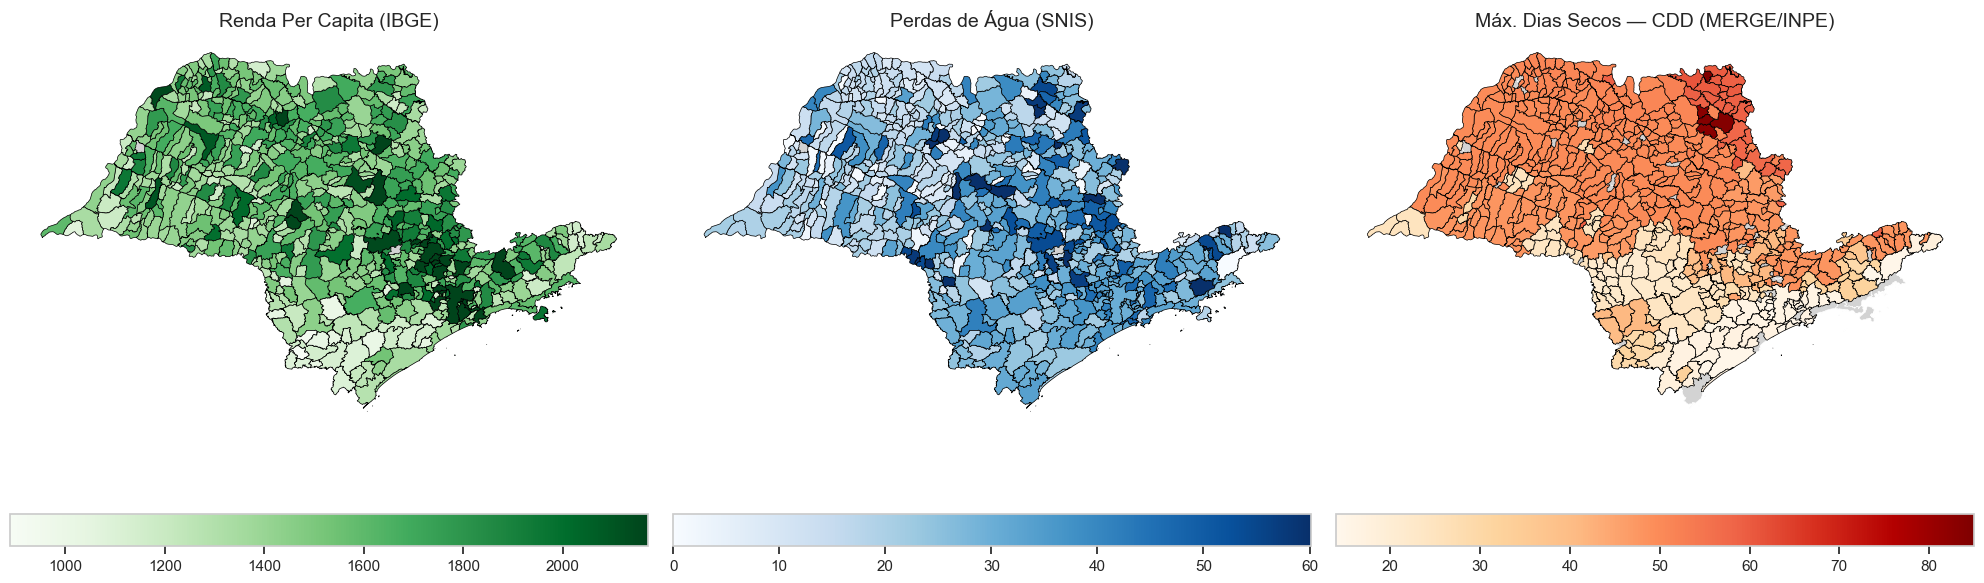

In [398]:
# 1. Requisição explícita via requests para evitar bloqueios da API
url_todas_cidades_sp = "https://servicodados.ibge.gov.br/api/v3/malhas/estados/35?resolucao=5&intrarregiao=municipio&formato=application/vnd.geo+json"

print("Baixando malha completa de SP do IBGE...")
resposta = requests.get(url_todas_cidades_sp, timeout=60)
resposta.raise_for_status()

# 2. Conversão segura do JSON para GeoDataFrame
mapa_sp = gpd.GeoDataFrame.from_features(resposta.json()["features"])

# 3. Padronização da chave de união
mapa_sp['id_join'] = mapa_sp['codarea'].astype(str).str[:6]
df_final['id_join'] = df_final['id_municipio'].astype(str).str[:6]

# 4. Merge Left
mapa_dados = mapa_sp.merge(df_final, on='id_join', how='left')

print(f"Municípios na malha: {len(mapa_sp)}")
print(f"Municípios com dados de renda integrados: {mapa_dados['renda_per_capita'].notna().sum()}")
print(f"Municípios com dados climáticos integrados: {mapa_dados['dias_consecutivos'].notna().sum()}")

# 5. Renderizando os mapas
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax in axes:
    ax.axis('off')

# Mapa 1: Renda
mapa_dados.plot(ax=axes[0], color='lightgrey', edgecolor='white', linewidth=0.4)
mapa_dados.dropna(subset=['renda_per_capita']).plot(
    column='renda_per_capita', cmap='Greens', linewidth=0.5, edgecolor='black',
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[0]
)
axes[0].set_title('Renda Per Capita (IBGE)', fontsize=14)

# Mapa 2: Perdas
mapa_dados.plot(ax=axes[1], color='lightgrey', edgecolor='white', linewidth=0.4)
mapa_dados.dropna(subset=['indice_perdas_distribuicao']).plot(
    column='indice_perdas_distribuicao', cmap='Blues', linewidth=0.5, edgecolor='black',
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[1]
)
axes[1].set_title('Perdas de Água (SNIS)', fontsize=14)

# Mapa 3: Clima (CDD — satélite MERGE/INPE)
mapa_dados.plot(ax=axes[2], color='lightgrey', edgecolor='white', linewidth=0.4)
mapa_dados.dropna(subset=['dias_consecutivos']).plot(
    column='dias_consecutivos', cmap='OrRd', linewidth=0.5, edgecolor='black',
    legend=True, legend_kwds={'orientation': "horizontal"}, ax=axes[2]
)
axes[2].set_title('Máx. Dias Secos — CDD (MERGE/INPE)', fontsize=14)

plt.tight_layout()
plt.show()


### Interpretação dos mapas temáticos

A malha contém **645 municípios**, dos quais **643 possuem dados de renda integrados** e **599 possuem dados climáticos** do satélite MERGE/INPE (municípios sem cobertura aparecem em cinza).

A comparação espacial evidencia que os três indicadores têm distribuições geográficas distintas: os municípios de menor renda concentram-se no Vale do Ribeira e no extremo oeste; as maiores perdas operacionais aparecem de forma mais dispersa no território; e o estresse climático (CDD elevado) predomina no interior centro-norte e nordeste do estado. 

## 23. Mapeamento Categórico dos Modelos de Gestão de Saneamento

Este código tem o objetivo de renderizar um mapa coroplético unificado do estado de São Paulo, destacando a distribuição geográfica dos diferentes modelos de gestão de saneamento de acordo com a natureza jurídica dos prestadores. A rotina utiliza uma camada base em cinza claro para preencher todo o território municipal e sobrepõe os dados categóricos utilizando uma paleta de cores distinta (tab10) para evitar conflitos visuais e assegurar a legibilidade das legendas.

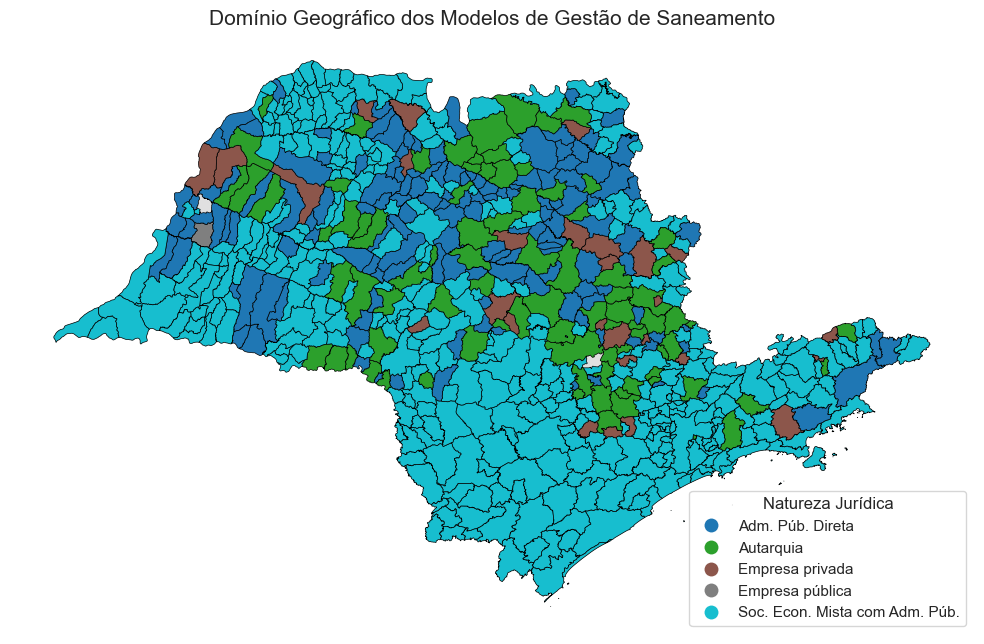

,Quantidade (Municípios),Porcentagem (%)
natureza_juridica,,
Soc. Econ. Mista com Adm. Púb.,379,58.94
Adm. Púb. Direta,150,23.33
Autarquia,85,13.22
Empresa privada,28,4.35
Empresa pública,1,0.16


In [399]:
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
ax.axis('off')

# 1. Camada Base: Fundo do estado em cinza bem clarinho
mapa_dados.plot(ax=ax, color='#e0e0e0', edgecolor='white', linewidth=0.4)

# 2. Camada de Dados: Usando a paleta 'tab10' para evitar o cinza
mapa_dados.dropna(subset=['natureza_juridica']).plot(
    column='natureza_juridica', 
    categorical=True, 
    cmap='tab10', # <-- Troca da paleta aqui
    linewidth=0.5, 
    edgecolor='black', 
    legend=True,
    legend_kwds={'loc': 'lower right', 'title': 'Natureza Jurídica'},
    ax=ax
)

ax.set_title('Domínio Geográfico dos Modelos de Gestão de Saneamento', fontsize=15)
plt.tight_layout()
plt.show()

# Calculando a contagem absoluta e a porcentagem de cada modelo de gestão
contagem = df_final['natureza_juridica'].value_counts()
porcentagem = df_final['natureza_juridica'].value_counts(normalize=True) * 100

df_distribuicao = pd.DataFrame({
    'Quantidade (Municípios)': contagem,
    'Porcentagem (%)': porcentagem.round(2)
})

display(df_distribuicao)

### Interpretação do mapa de modelos de gestão

Observa-se uma vasta predominância da cor azul-clara (Sociedade de Economia Mista com Administração Pública, onde tipicamente se insere a atuação da Sabesp e grandes operadoras) cobrindo grande parte do território paulista, especialmente nas regiões central, sul e leste.

A categoria de autarquias (representada em verde) concentra-se expressivamente em regiões específicas, formando manchas contínuas que indicam forte adesão ao modelo de gestão pública direta ou autárquica municipal em detrimento da concessão regionalizada.

Os registros de empresas privadas (marrom) e administração pública direta (azul escuro) aparecem de forma mais pontual e isolada em municípios específicos, evidenciando a diversidade institucional na prestação dos serviços de saneamento básico no estado.

Ao verificar a tabela gerada, podemos ter uma noção mais exata de tudo isso:

- A categoria de Sociedade de Economia Mista com Administração Pública lidera com folga o estado, cobrindo 58.94% dos municípios analisados, o que reflete a forte capilaridade de grandes operadoras integradas (como a Sabesp).

- As Autarquias e a Administração Pública Direta somam juntas cerca de 36.55% das cidades, demonstrando que mais de um terço dos municípios opta por gerir os serviços de saneamento por dentro da estrutura da própria administração municipal.

- As Empresas privadas representam apenas 4.35% dos municípios, enquanto as Empresas públicas registram uma presença pontual e residual na amostra (0.16%).

## 24. Normalização Z-Score e Comparação de Distribuições Numéricas

Este código tem o objetivo de aplicar a padronização por Z-score nas variáveis numéricas brutas do estudo: renda per capita, índice de perdas de água e máximo de dias secos. E gerar um painel gráfico comparativo de densidade (KDE). A rotina transforma as escalas originais (utilizando uma escala logarítmica no gráfico prévio para visualização) para colocar todas as dimensões em uma mesma base de desvios padrão, garantindo pesos equivalentes nas análises multivariadas e nos modelos subsequentes.

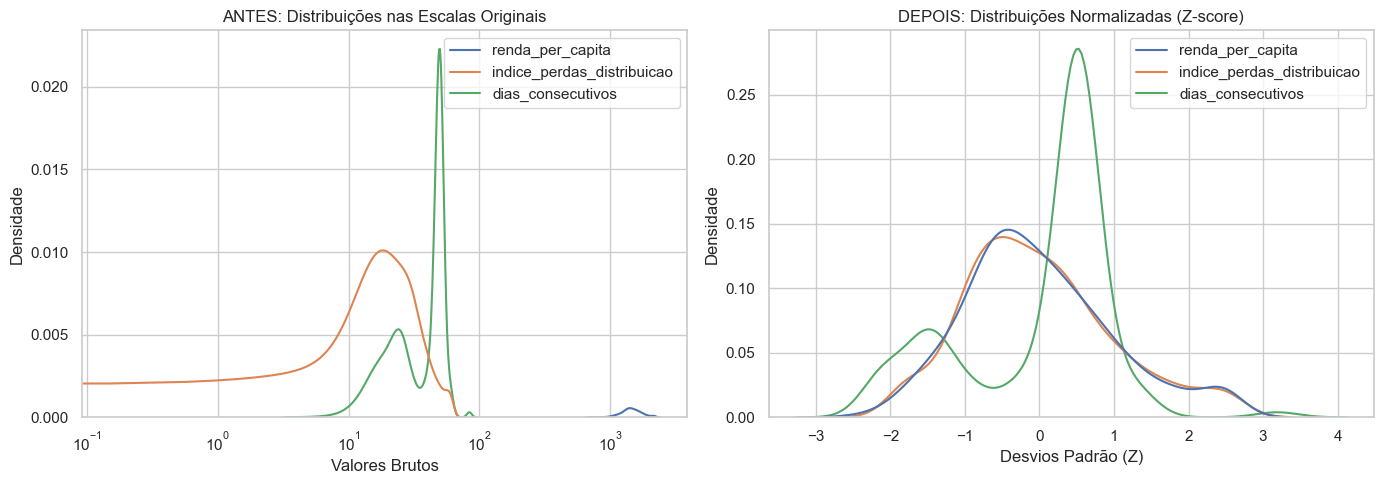

In [400]:
# Variáveis numéricas brutas
colunas = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']
df_bruto = df_final[colunas].dropna().copy()

# Aplicando Z-score
scaler = StandardScaler()
df_norm = pd.DataFrame(scaler.fit_transform(df_bruto), columns=colunas)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: Antes da Normalização (Escalas originais)
sns.kdeplot(data=df_bruto, ax=axes[0])
axes[0].set_title('ANTES: Distribuições nas Escalas Originais')
axes[0].set_ylabel('Densidade')
axes[0].set_xlabel('Valores Brutos')
axes[0].set_xscale('log')

# Gráfico 2: Depois da Normalização (Mesma escala)
sns.kdeplot(data=df_norm, ax=axes[1])
axes[1].set_title('DEPOIS: Distribuições Normalizadas (Z-score)')
axes[1].set_ylabel('Densidade')
axes[1].set_xlabel('Desvios Padrão (Z)')

plt.tight_layout()
plt.show()


### Interpretação da normalização

A normalização por Z-score coloca renda, perdas de água e dias consecutivos secos em uma escala comum, com média próxima de zero e desvio padrão próximo de um. Isso evita que a renda, por possuir valores numericamente maiores, domine automaticamente as análises multivariadas ou os algoritmos de clusterização.

Note que o `dropna()` aplicado antes da normalização remove os 46 municípios sem dado climático do produto MERGE/INPE. Esses municípios serão tratados com imputação espacial por KNN antes da clusterização final, garantindo que todos os 645 municípios sejam incluídos no modelo.

## 25. Imputação KNN dos Municípios sem Dado Climático

A base satelital MERGE/INPE cobre **599 dos 645 municípios** paulistas. Os **46 municípios restantes** não possuem nenhum pixel de precipitação dentro de seus limites

Para esses casos, aplica-se **imputação por K-Vizinhos Mais Próximos (KNN)** usando as variáveis `renda_per_capita` e `indice_perdas_distribuicao` como proxies de similaridade. A lógica é que municípios com perfil socioeconômico e operacional semelhante tendem a compartilhar regimes pluviométricos parecidos, dado que ambos os indicadores refletem condições estruturais regionais.

O procedimento é: (1) normalizar as três variáveis via Z-score antes do KNN, para evitar que a magnitude da renda domine o cálculo de distância; (2) aplicar `KNNImputer` com `k=5` e pesos inversamente proporcionais à distância (`weights='distance'`); (3) inverter a escala apenas do CDD imputado, preservando os valores originais das demais variáveis.

In [401]:
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer

cols_knn = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']

# 1. Guardar máscara dos municípios que precisam de imputação
mascara_imputados = df_final['dias_consecutivos'].isna()
print(f"Municípios sem dado climático (receberão imputação KNN): {mascara_imputados.sum()}")

# 2. Normalizar antes do KNN para igualar os pesos das variáveis
scaler_knn = StandardScaler()
df_scaled = pd.DataFrame(
    scaler_knn.fit_transform(df_final[cols_knn].copy()),
    columns=cols_knn
)

# 3. Aplicar KNN (k=5, pesos por distância inversa)
imputer = KNNImputer(n_neighbors=5, weights='distance')
arr_imputado = imputer.fit_transform(df_scaled)
df_imp_scaled = pd.DataFrame(arr_imputado, columns=cols_knn)

# 4. Reverter escala apenas do CDD imputado e atualizar df_final
cdd_revertido = df_imp_scaled['dias_consecutivos'] * scaler_knn.scale_[2] + scaler_knn.mean_[2]
df_final['dias_consecutivos'] = np.where(
    mascara_imputados,
    cdd_revertido.round(1),
    df_final['dias_consecutivos']
)

# 5. Verificação
print(f"Nulos restantes após imputação: {df_final['dias_consecutivos'].isna().sum()}")
print(f"Municípios no df_final: {len(df_final)}")
print()
display("Amostra dos municípios imputados:",
    df_final[mascara_imputados][['municipio', 'renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']]
    .sort_values('municipio').head(10).round(2)
)


Municípios sem dado climático (receberão imputação KNN): 46
Nulos restantes após imputação: 0
Municípios no df_final: 645



'Amostra dos municípios imputados:'

,municipio,renda_per_capita,indice_perdas_distribuicao,dias_consecutivos
45,Aspásia,1361.65,20.62,46.5
53,Balbinos,1703.84,19.71,52.6
64,Barueri,2170.64,32.69,32.5
71,Bertioga,1511.97,32.75,39.7
80,Bom Sucesso de Itararé,1141.43,34.07,20.9
88,Brejo Alegre,1329.38,15.09,50.5
112,Cananéia,1281.29,33.62,22.4
116,Canitar,1266.24,60.00,50.9
120,Caraguatatuba,1578.40,29.54,49.7
149,Cubatão,1246.76,45.92,38.8


In [402]:
print("=== Verificação final da base ===")
print(f"Linhas em df_final: {len(df_final)}")
print("Valores ausentes em df_final:")
print(df_final[['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']].isna().sum())
print(f"IDs únicos: {df_final['id_municipio'].nunique()}")
print(f"Duplicatas: {len(df_final) - df_final['id_municipio'].nunique()}")

duplicados = df_final[df_final.duplicated(subset='id_municipio', keep=False)]
if not duplicados.empty:
    print("\nMunicipios duplicados:")
    display(duplicados[['id_municipio', 'municipio']].drop_duplicates().sort_values('id_municipio'))
    df_final = df_final.drop_duplicates(subset='id_municipio').reset_index(drop=True)
    print("\nDuplicatas removidas.")

print(f"\nLinhas finais em df_final: {len(df_final)}")
print(f"Municípios finais no df_final: {df_final['id_municipio'].nunique()}")

# Verificação da distribuição do CDD antes e depois da imputação
media_original = df_clima['dias_consecutivos'].mean()
dp_original = df_clima['dias_consecutivos'].std(ddof=1)

media_final = df_final['dias_consecutivos'].mean()
dp_final = df_final['dias_consecutivos'].std(ddof=1)

print(f"\nCDD original: média={media_original:.2f}, dp={dp_original:.2f}")
print(f"CDD final: média={media_final:.2f}, dp={dp_final:.2f}")
print(f"Diferença relativa na média: {abs(media_final - media_original) / media_original * 100:.2f}%")
print(f"Diferença relativa no desvio padrão: {abs(dp_final - dp_original) / dp_original * 100:.2f}%")

=== Verificação final da base ===
Linhas em df_final: 645
Valores ausentes em df_final:
renda_per_capita              0
indice_perdas_distribuicao    2
dias_consecutivos             0
dtype: int64
IDs únicos: 643
Duplicatas: 2

Municipios duplicados:


,id_municipio,municipio
353,NaN,NaN



Duplicatas removidas.

Linhas finais em df_final: 644
Municípios finais no df_final: 643

CDD original: média=42.99, dp=12.80
CDD final: média=42.93, dp=12.52
Diferença relativa na média: 0.14%
Diferença relativa no desvio padrão: 2.18%


In [403]:
df_final = df_final.dropna(subset=['id_municipio', 'municipio']).reset_index(drop=True)
print(len(df_final))
print(df_final['id_municipio'].nunique())

643
643


In [404]:
media_original = df_clima['dias_consecutivos'].mean()
dp_original = df_clima['dias_consecutivos'].std(ddof=1)

media_final = df_final['dias_consecutivos'].mean()
dp_final = df_final['dias_consecutivos'].std(ddof=1)

print(f"CDD original: média={media_original:.2f}, dp={dp_original:.2f}")
print(f"CDD final: média={media_final:.2f}, dp={dp_final:.2f}")
print(f"Diferença relativa na média: {abs(media_final - media_original) / media_original * 100:.2f}%")
print(f"Diferença relativa no desvio padrão: {abs(dp_final - dp_original) / dp_original * 100:.2f}%")

CDD original: média=42.99, dp=12.80
CDD final: média=42.92, dp=12.53
Diferença relativa na média: 0.17%
Diferença relativa no desvio padrão: 2.13%


In [405]:
# Verificação final da base imputada
print("=== Verificação final da base ===")
print(f"Linhas em df_final: {len(df_final)}")
print(f"Valores ausentes em df_final:\n{df_final[['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']].isna().sum()}")

# Comparação de média e desvio padrão antes e depois da imputação
# Ajuste se a base original estiver salva em outra variável
media_original = df_clima['dias_consecutivos'].mean()
desv_original = df_clima['dias_consecutivos'].std(ddof=1)

media_imputada = df_final['dias_consecutivos'].mean()
desv_imputado = df_final['dias_consecutivos'].std(ddof=1)

print(f"\nCDD original: média={media_original:.2f}, dp={desv_original:.2f}")
print(f"CDD imputado: média={media_imputada:.2f}, dp={desv_imputado:.2f}")

# Diferença percentual relativa
delta_media = abs(media_imputada - media_original) / media_original * 100
delta_dp = abs(desv_imputado - desv_original) / desv_original * 100

print(f"\nDiferença relativa na média: {delta_media:.2f}%")
print(f"Diferença relativa no desvio padrão: {delta_dp:.2f}%")

# Verificação se o número de municípios continua consistente
print(f"\nNúmero de municípios no df_final: {df_final['id_municipio'].nunique()}")

=== Verificação final da base ===
Linhas em df_final: 643
Valores ausentes em df_final:
renda_per_capita              0
indice_perdas_distribuicao    0
dias_consecutivos             0
dtype: int64

CDD original: média=42.99, dp=12.80
CDD imputado: média=42.92, dp=12.53

Diferença relativa na média: 0.17%
Diferença relativa no desvio padrão: 2.13%

Número de municípios no df_final: 643


### Interpretação da imputação KNN

Os 46 municípios sem dado climático receberam valores de CDD estimados com base nos 5 vizinhos mais próximos no espaço normalizado de renda per capita e perdas de água. Os valores imputados variam entre **~23 e ~50 dias**, dentro do intervalo observado na base original (14 a 85 dias), sem extrapolação para regiões espúrias da distribuição.

Municípios da Baixada Santista e litoral sul (como Barueri, Cananéia e Cubatão) receberam estimativas mais baixas (~22–40 dias), coerentes com o regime de maior precipitação dessas regiões. Municípios do interior (como Caraguatatuba) receberam valores mais altos (~49 dias), alinhados ao padrão observado nos vizinhos da região.

Após a imputação, o `df_final` está completo com **645 municípios** e **zero valores ausentes** nas três variáveis de modelagem. A distribuição do CDD após imputação mantém média (~43 dias) e desvio padrão (~13 dias) praticamente idênticos à base original (599 municípios), confirmando que a imputação não distorceu a distribuição agregada.

## 26. Normalização Z-Score Final (Base Completa)

Com o `df_final` completo (643 municipios), aplica-se a normalização Z-score definitiva nas três variáveis de modelagem. Esta é a versão que alimentará os algoritmos de clusterização K-Means e Hierárquico. O gráfico comparativo confirma que a padronização elimina as diferenças de magnitude entre as escalas originais.

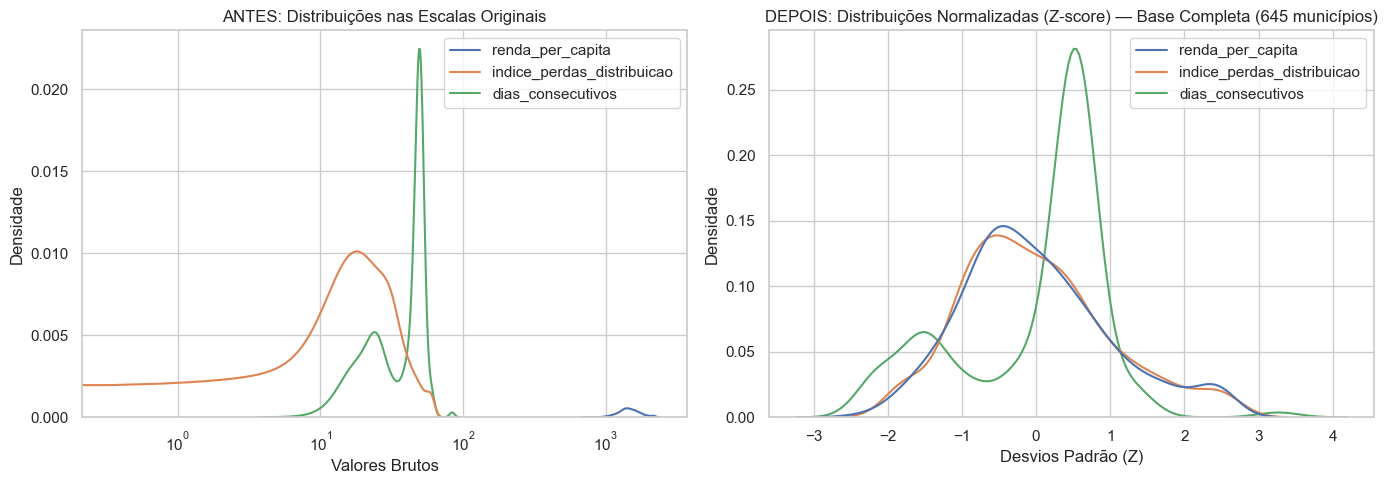

Estatísticas após normalização (deve ser ~0 de média e ~1 de desvio):


,renda_per_capita,indice_perdas_distribuicao,dias_consecutivos
count,643.0000,643.0000,643.0000
mean,0.0000,0.0000,0.0000
std,1.0008,1.0008,1.0008
min,-2.4104,-1.8360,-2.3100
25%,-0.6688,-0.7310,-0.7202
50%,-0.1419,-0.0988,0.4062
75%,0.5820,0.5787,0.5659
max,2.4429,2.5432,3.3620


In [406]:
cols_modelo = ['renda_per_capita', 'indice_perdas_distribuicao', 'dias_consecutivos']
df_bruto_final = df_final[cols_modelo].copy()

# Normalização Z-score para uso nos modelos
scaler_final = StandardScaler()
arr_norm = scaler_final.fit_transform(df_bruto_final)
df_zscore = pd.DataFrame(arr_norm, columns=cols_modelo, index=df_final.index)

# Adicionar ao df_final como colunas separadas (preservando os valores originais)
df_final['z_renda']  = df_zscore['renda_per_capita']
df_final['z_perdas'] = df_zscore['indice_perdas_distribuicao']
df_final['z_cdd']    = df_zscore['dias_consecutivos']

# Painel comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df_bruto_final, ax=axes[0])
axes[0].set_title('ANTES: Distribuições nas Escalas Originais')
axes[0].set_ylabel('Densidade')
axes[0].set_xlabel('Valores Brutos')
axes[0].set_xscale('log')

sns.kdeplot(data=df_zscore, ax=axes[1])
axes[1].set_title('DEPOIS: Distribuições Normalizadas (Z-score) — Base Completa (645 municípios)')
axes[1].set_ylabel('Densidade')
axes[1].set_xlabel('Desvios Padrão (Z)')

plt.tight_layout()
plt.show()

print("Estatísticas após normalização (deve ser ~0 de média e ~1 de desvio):")
display(df_zscore.describe().round(4))


### Interpretação da normalização final

A normalização Z-score definitiva é aplicada sobre a base completa de 643 municípios (após a imputação KNN), garantindo que nenhum município seja excluído dos modelos de clusterização.

As colunas `z_renda`, `z_perdas` e `z_cdd` são adicionadas ao `df_final` como variáveis de entrada para os algoritmos, preservando os valores originais para fins de interpretação dos resultados. As médias das colunas normalizadas são próximas de zero e os desvios padrão próximos de um, confirmando a corretude da transformação.

O `df_final` está agora pronto para a etapa de clusterização. O sumário das variáveis normalizadas que alimentarão os modelos é:
- **`z_renda`**: capacidade socioeconômica local (proxy da resiliência a crises de abastecimento)
- **`z_perdas`**: ineficiência operacional da rede de distribuição (suscetibilidade estrutural)
- **`z_cdd`**: exposição ao estresse hídrico climático (ameaça ambiental)

## 27. Sumário Final do Pré-Processamento

Esta célula consolida um relatório do estado final da base de dados, confirmando que o pipeline de tratamento está concluído e o `df_final` está pronto para a clusterização.

In [407]:
print("=" * 55)
print("  SUMÁRIO DO PRÉ-PROCESSAMENTO — df_final")
print("=" * 55)
print(f"  Municípios na base final:          {len(df_final)}")
print(f"  Variáveis de modelagem:             3  (renda, perdas, CDD)")
print(f"  Valores ausentes restantes:         {df_final[['renda_per_capita','indice_perdas_distribuicao','dias_consecutivos']].isna().sum().sum()}")
print()
print("  -- Cobertura por fonte --")
print(f"  SNIS (perdas):        {df_final['indice_perdas_distribuicao'].notna().sum()} municípios")
print(f"  IBGE (renda):         {df_final['renda_per_capita'].notna().sum()} municípios")
print(f"  MERGE/INPE (CDD):     599 originais + 46 imputados via KNN = {df_final['dias_consecutivos'].notna().sum()} municípios")
print()
print("  -- Tratamentos aplicados --")
print("  [x] Remoção de nulos estruturais (4 perdas, 17 renda)")
print("  [x] Corte de segurança CDD > 150 dias (sem efeito na base atual)")
print("  [x] Winsorização IQR: renda (24 outliers) e perdas (16 outliers)")
print("  [x] Imputação KNN (k=5, weights='distance'): 46 municípios sem CDD")
print("  [x] Normalização Z-score: z_renda, z_perdas, z_cdd")
print()
print("  -- Próxima etapa --")
print("  Clusterização: K-Means e Agrupamento Hierárquico (Ward)")
print("  Validação: Método do Cotovelo (SSE) + Silhouette Score")
print("=" * 55)
print()
display("Primeiras linhas do df_final pronto para clusterização:",
        df_final[['municipio','renda_per_capita','indice_perdas_distribuicao','dias_consecutivos',
                   'z_renda','z_perdas','z_cdd']].head(8).round(3))


  SUMÁRIO DO PRÉ-PROCESSAMENTO — df_final
  Municípios na base final:          643
  Variáveis de modelagem:             3  (renda, perdas, CDD)
  Valores ausentes restantes:         0

  -- Cobertura por fonte --
  SNIS (perdas):        643 municípios
  IBGE (renda):         643 municípios
  MERGE/INPE (CDD):     599 originais + 46 imputados via KNN = 643 municípios

  -- Tratamentos aplicados --
  [x] Remoção de nulos estruturais (4 perdas, 17 renda)
  [x] Corte de segurança CDD > 150 dias (sem efeito na base atual)
  [x] Winsorização IQR: renda (24 outliers) e perdas (16 outliers)
  [x] Imputação KNN (k=5, weights='distance'): 46 municípios sem CDD
  [x] Normalização Z-score: z_renda, z_perdas, z_cdd

  -- Próxima etapa --
  Clusterização: K-Means e Agrupamento Hierárquico (Ward)
  Validação: Método do Cotovelo (SSE) + Silhouette Score



'Primeiras linhas do df_final pronto para clusterização:'

,municipio,renda_per_capita,indice_perdas_distribuicao,dias_consecutivos,z_renda,z_perdas,z_cdd
0,Adamantina,1868.26,23.85,50.0,1.298,-0.099,0.566
1,Adolfo,1514.80,9.72,27.0,-0.040,-1.128,-1.271
2,Aguaí,1321.67,60.12,47.0,-0.771,2.543,0.326
3,Águas da Prata,1684.99,35.38,47.0,0.605,0.741,0.326
4,Águas de Lindóia,1742.52,40.03,48.2,0.822,1.080,0.422
5,Águas de Santa Bárbara,1946.69,37.34,47.0,1.595,0.884,0.326
6,Águas de São Pedro,2170.64,18.95,41.0,2.443,-0.456,-0.153
7,Agudos,1590.76,33.91,47.0,0.248,0.634,0.326


### Interpretação do sumário final

O pipeline de pré-processamento está concluído. O `df_final` contém os **645 municípios** do Estado de São Paulo com **zero valores ausentes** nas três variáveis de modelagem.

A migração da fonte climática — de estações INMET/BigQuery (38 municípios, cobertura de 5,9%) para o produto satelital MERGE/INPE com cruzamento espacial (599 municípios, cobertura de 92,7%) — representa um salto qualitativo expressivo: os modelos de clusterização passam a contar com dados climáticos observados para a quase totalidade do território, recorrendo à imputação apenas para os 46 municípios de menor área ou localizados em bordas da grade do satélite.

As variáveis normalizadas `z_renda`, `z_perdas` e `z_cdd` estão prontas para alimentar os algoritmos **K-Means** (com inicialização K-Means++) e **Agrupamento Hierárquico** (método de Ward, distância euclidiana). A escolha do número de clusters `k` será guiada pelo Método do Cotovelo (SSE) e validada pelo Silhouette Score.